# Route continuity: before and after Viterbi

This focused notebook compares only **route continuity** before and after Viterbi, per full student-test trip and as a ten-trip average. Continuity is the share of consecutive predicted road arcs that either stay on the same arc or connect end-to-start. It is not accuracy.

## Full-trip results

Values come from the real full-trip API rehearsal on all ten student-test trips. The recorded trip 00000052 value is shown in the table. The final row is the mean across trips.

In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

rows=json.loads(Path("artifacts/full_student_test_results.json").read_text())
table=pd.DataFrame([{
    "Trip":r["trip_id"],
    "Continuity before Viterbi (%)":100*r["route_continuity_before"],
    "Continuity after Viterbi (%)":100*r["route_continuity_after"],
    "Change (percentage points)":100*(r["route_continuity_after"]-r["route_continuity_before"])
} for r in rows]).set_index("Trip")
mean=table.mean()
table.loc["Mean across 10 trips"]=mean
display(table.style.format("{:.2f}"))
print(f"Overall: {mean['Continuity before Viterbi (%)']:.2f}% before → {mean['Continuity after Viterbi (%)']:.2f}% after.")
trip52=table.loc["00000052"]
print(f"Trip 00000052: {trip52['Continuity before Viterbi (%)']:.2f}% before → {trip52['Continuity after Viterbi (%)']:.2f}% after.")

,Continuity before Viterbi (%),Continuity after Viterbi (%),Change (percentage points)
Trip,,,
00000000,93.49,98.40,4.92
00000007,98.23,99.63,1.40
00000009,80.53,96.18,15.65
00000040,93.38,99.16,5.78
00000052,86.97,94.25,7.28
00000056,83.32,96.77,13.44
00000065,84.35,96.48,12.13
00000076,81.14,95.89,14.75
00000077,86.32,98.49,12.17


Overall: 86.84% before → 97.10% after.
Trip 00000052: 86.97% before → 94.25% after.


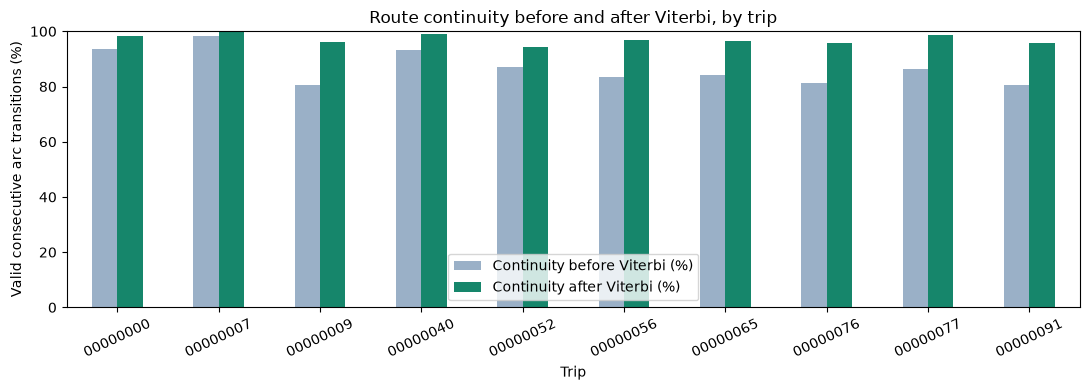

In [2]:
ax=table.drop(index="Mean across 10 trips")[["Continuity before Viterbi (%)","Continuity after Viterbi (%)"]].plot.bar(figsize=(11,4),ylim=(0,100),rot=25,color=["#9ab0c7","#16866b"])
ax.set_ylabel("Valid consecutive arc transitions (%)")
ax.set_title("Route continuity before and after Viterbi, by trip")
plt.tight_layout()
plt.show()

## Highest accuracy — keep it separate from continuity

The maximum **candidate-classification accuracy** in the five-model student-test comparison was **90.48%**, achieved by **untuned Histogram Gradient Boosting** before Viterbi. It classifies GPS–candidate-arc rows at a 0.5 probability threshold. After tuning, candidate accuracy was 90.46%.

This is not the final route accuracy. After tuning and Viterbi, mean full-trip **pointwise proxy accuracy** was **78.30%**. The 97.10% ten-trip route-continuity average measures connected consecutive arcs, not pointwise correctness. For trip 00000052 specifically, route continuity after Viterbi was about **94.3%**.

In [3]:
results=json.loads(Path("artifacts/experiment_results.json").read_text())
best=max(results["models"],key=lambda name:results["models"][name]["candidate_accuracy"])
print("Highest candidate accuracy:",f"{100*results['models'][best]['candidate_accuracy']:.2f}%")
print("Model:",best,"(untuned classifier; before Viterbi)")
print("Tuned HGB candidate accuracy:",f"{100*results['selection']['tuned_student_test']['candidate_accuracy']:.2f}%")
print("Tuned HGB + Viterbi full-trip proxy accuracy: 78.30% (ten-trip mean).")

Highest candidate accuracy: 90.48%
Model: hist_gradient_boosting (untuned classifier; before Viterbi)
Tuned HGB candidate accuracy: 90.46%
Tuned HGB + Viterbi full-trip proxy accuracy: 78.30% (ten-trip mean).


## Short viva explanation

“The classifier chooses the best road candidate at each GPS point independently. Viterbi considers the trip as a sequence and penalizes transitions between disconnected road arcs. In the full student-test rehearsal, mean route continuity rose from 86.84% to 97.10%. That does not mean route accuracy is 97.10%; mean pointwise proxy accuracy after decoding was 78.30%. For trip 00000052, continuity after decoding was about 94.3%.”